In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnext50_32x4d
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [ ]:
class ResNeXtBottleneck(nn.Module):
    expansion: int = 4
    ##in_channels - фактична кількість каналів, яка приходить на вхід даного блока
    ##base_channel_coefficient - абстрактний коефіцієнт поточного блоку, який використовується для обчислення інших параметрів (з літератури оригінальної)
    ##cardinality - кількість паралельних груп в груповій згортці
    ##first_step_group_width - ширина(кількість каналів) однієї групи на першому етапі
    ##current_one_group_channels - ширина(кількість каналів) однієї групи на поточному етапі
    ##total_groups_channels - сумарна ширина(кількість каналів) для всіх груп

    def __init__(self, in_channels: int, base_channel_coefficient: int, stride: int = 1, cardinality: int = 32, first_step_group_width: int = 4):
        super(ResNeXtBottleneck, self).__init__()

        current_one_group_channels = int(base_channel_coefficient * (first_step_group_width / 64.0))
        total_groups_channels = cardinality * current_one_group_channels ##128

        self.conv1 = nn.Conv2d(in_channels, total_groups_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(total_groups_channels)

        self.conv2 = nn.Conv2d(
            total_groups_channels, total_groups_channels, kernel_size=3, stride=stride,
            padding=1, groups=cardinality, bias=False
        )
        self.bn2 = nn.BatchNorm2d(total_groups_channels)

        self.conv3 = nn.Conv2d(total_groups_channels, base_channel_coefficient * self.expansion, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(base_channel_coefficient * self.expansion)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != base_channel_coefficient * self.expansion:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, base_channel_coefficient * self.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(base_channel_coefficient * self.expansion)
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = F.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        out += self.shortcut(x)
        return F.relu(out)

In [ ]:
class ResNeXt50FromScratch(nn.Module):
    def __init__(self, feature_dim: int = 32, cardinality: int = 32, first_step_group_width: int = 4):
        super(ResNeXt50FromScratch, self).__init__()
        self.in_channels = 64
        self.cardinality = cardinality
        self.first_step_group_width = first_step_group_width

        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)

        self.layer1 = self._make_layer(base_channel_coefficient=64, blocks=3, stride=1)
        self.layer2 = self._make_layer(base_channel_coefficient=128, blocks=4, stride=2)
        self.layer3 = self._make_layer(base_channel_coefficient=256, blocks=6, stride=2)
        self.layer4 = self._make_layer(base_channel_coefficient=512, blocks=3, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Sequential(
            nn.Linear(512 * ResNeXtBottleneck.expansion, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, feature_dim),
            nn.BatchNorm1d(feature_dim),
            nn.ReLU()
        )

    def _make_layer(self, base_channel_coefficient: int, blocks: int, stride: int) -> nn.Sequential:
        strides = [stride] + [1] * (blocks - 1)
        layers = []
        for s in strides:
            layers.append(
                ResNeXtBottleneck(
                    self.in_channels, base_channel_coefficient, stride=s,
                    cardinality=self.cardinality, first_step_group_width=self.first_step_group_width
                )
            )
            self.in_channels = base_channel_coefficient * ResNeXtBottleneck.expansion
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)
        return out

In [ ]:
class ResNeXt50Classifier(nn.Module):
    def __init__(self, num_classes: int = 10, cardinality: int = 32, first_step_group_width: int = 4):
        super(ResNeXt50Classifier, self).__init__()
        self.backbone = ResNeXt50FromScratch(feature_dim=128, cardinality=cardinality, first_step_group_width=first_step_group_width)

        self.backbone.fc = nn.Sequential(
            nn.Linear(512 * ResNeXtBottleneck.expansion, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

In [ ]:
def get_feature_extractor(model_type: str = 'custom', feature_dim: int = 32) -> nn.Module:
    if model_type == 'custom':
        print("Ініціалізація ВЛАСНОЇ архітектури ResNeXt-50...")
        return ResNeXt50FromScratch(feature_dim=feature_dim)
    elif model_type == 'torchvision':
        print("Ініціалізація ГОТОВОЇ архітектури ResNeXt-50 з torchvision")
        base_model = resnext50_32x4d(weights=None)
        base_model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        base_model.maxpool = nn.Identity()
        in_features = base_model.fc.in_features
        base_model.fc = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, feature_dim),
            nn.BatchNorm1d(feature_dim),
            nn.ReLU()
        )
        return base_model
    else:
        raise ValueError(f"Невідомий тип моделі: '{model_type}'. Очікується 'custom' або 'torchvision'.")


In [ ]:
def get_classifier(model_type: str = 'custom', num_classes: int = 10) -> nn.Module:
    if model_type == 'custom':
        print("Ініціалізація ВЛАСНОГО класифікатора ResNeXt-50...")
        return ResNeXt50Classifier(num_classes=num_classes)
    elif model_type == 'torchvision':
        print("Ініціалізація ГОТОВОГО класифікатора ResNeXt-50 з torchvision...")
        base_model = resnext50_32x4d(weights=None)
        base_model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        base_model.maxpool = nn.Identity()
        in_features = base_model.fc.in_features
        base_model.fc = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
        return base_model
    else:
        raise ValueError(f"Невідомий тип моделі: '{model_type}'. Очікується 'custom' або 'torchvision'.")

In [ ]:
class SiameseNet(nn.Module):
    def __init__(self, feature_extractor: nn.Module, feature_dim: int = 32):
        super(SiameseNet, self).__init__()
        self.feature_extractor = feature_extractor
        self.similarity_head = nn.Sequential(
            nn.Linear(feature_dim * 2, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Linear(16, 4),
            nn.BatchNorm1d(4),
            nn.ReLU(),
            nn.Linear(4, 1),
            nn.Sigmoid()
        )

    def forward(self, first_image: torch.Tensor, second_image: torch.Tensor) -> torch.Tensor:
        first_image_features = self.feature_extractor(first_image)
        second_image_features = self.feature_extractor(second_image)
        combined_features = torch.cat((first_image_features, second_image_features), dim=1)
        similarity = self.similarity_head(combined_features)
        return similarity

In [ ]:
class SiameseFashionMNIST(Dataset):
    def __init__(self, mnist_dataset):
        self.dataset = mnist_dataset
        self.labels = np.array(mnist_dataset.targets)
        self.data = mnist_dataset.data
        self.group_indices = [np.where(self.labels == i)[0] for i in range(10)]

    def __getitem__(self, index: int):
        first_image_index = index % len(self.dataset)
        first_label = self.labels[first_image_index]
        first_image = self.data[first_image_index].unsqueeze(0).float() / 255.0

        match_group = np.random.choice([True, False])
        if match_group:
            second_image_index = np.random.choice(self.group_indices[first_label])
            target = torch.tensor([1.0], dtype=torch.float32)
        else:
            diff_label = np.random.choice([l for l in range(10) if l != first_label])
            second_image_index = np.random.choice(self.group_indices[diff_label])
            target = torch.tensor([0.0], dtype=torch.float32)

        second_image = self.data[second_image_index].unsqueeze(0).float() / 255.0
        return first_image, second_image, target

    def __len__(self) -> int:
        return len(self.dataset)

In [ ]:
def show_model_predictions(siamese_model: nn.Module, test_dataset: Dataset, device: torch.device, examples_amount: int = 6):
    siamese_model.eval()
    siamese_dataset = SiameseFashionMNIST(test_dataset)
    loader = DataLoader(siamese_dataset, batch_size=examples_amount, shuffle=True)

    first_image, second_image, target = next(iter(loader))
    with torch.no_grad():
        pred_sim = siamese_model(first_image.to(device), second_image.to(device)).cpu().numpy()

    fig, axs = plt.subplots(2, examples_amount, figsize=(14, 5))
    for idx in range(examples_amount):
        axs[0, idx].imshow(first_image[idx][0].numpy(), cmap='viridis')
        axs[0, idx].set_title(f"Image A\nActual: {int(target[idx].item() * 100)}%")
        axs[0, idx].axis('off')

        axs[1, idx].imshow(second_image[idx][0].numpy(), cmap='viridis')
        axs[1, idx].set_title(f"Image B\nPredicted: {int(pred_sim[idx][0] * 100)}%")
        axs[1, idx].axis('off')

    plt.tight_layout()
    plt.savefig('siamese_predictions_result.png')
    plt.show()

In [ ]:
def visualize_tsne(feature_extractor: nn.Module, test_loader: DataLoader, device: torch.device):
    feature_extractor.eval()
    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            features = feature_extractor(images)
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())

    features_arr = np.concatenate(all_features, axis=0)
    labels_arr = np.concatenate(all_labels, axis=0)

    print("Обчислення t-SNE проекції на 2D площину...")
    tsne = TSNE(n_components=2, init='pca', random_state=42, n_iter=500, verbose=1)
    tsne_results = tsne.fit_transform(features_arr)

    categories = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    colors = plt.cm.rainbow(np.linspace(0, 1, 10))

    plt.figure(figsize=(10, 10))
    for idx, (color, label) in enumerate(zip(colors, categories)):
        mask = labels_arr == idx
        plt.scatter(tsne_results[mask, 0], tsne_results[mask, 1],
                    c=[color], label=label, alpha=0.7, s=15)

    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.title('t-SNE on Fashion-MNIST Testing Samples (ResNeXt-50 Features)')
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.savefig('clothes_tsne_resnext50.png')
    plt.show()

In [ ]:
def evaluate_siamese_metrics(siamese_model: nn.Module, test_dataset: Dataset, device: torch.device, threshold: float = 0.5):
    siamese_model.eval()
    siamese_test_ds = SiameseFashionMNIST(test_dataset)
    test_loader = DataLoader(siamese_test_ds, batch_size=256, shuffle=False)

    all_targets = []
    all_preds_prob = []

    with torch.no_grad():
        for first_image, second_image, target in test_loader:
            first_image, second_image = first_image.to(device), second_image.to(device)
            preds = siamese_model(first_image, second_image).cpu().squeeze().numpy()

            all_preds_prob.extend(preds)
            all_targets.extend(target.numpy().squeeze())

    all_targets = np.array(all_targets)
    all_preds_prob = np.array(all_preds_prob)
    all_preds_binary = (all_preds_prob >= threshold).astype(int)

    auc_score = roc_auc_score(all_targets, all_preds_prob)
    cm = confusion_matrix(all_targets, all_preds_binary)

    print("\n" + "="*50)
    print("      ТОЧНІ ФІНАЛЬНІ ПОКАЗНИКИ ЯКОСТІ МЕРЕЖІ")
    print("="*50)
    print(f"ROC-AUC Score: {auc_score:.4f}\n")
    print("Детальний звіт класифікації (Classification Report):")
    print(classification_report(all_targets, all_preds_binary, target_names=['Різні класи (0)', 'Один клас (1)'], digits=4))

    fig, axs = plt.subplots(1, 2, figsize=(13, 5))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axs[0],
                xticklabels=['Різні (0)', 'Один (1)'],
                yticklabels=['Різні (0)', 'Один (1)'])
    axs[0].set_title('Матриця помилок (Confusion Matrix)')
    axs[0].set_xlabel('Передбачено мережею')
    axs[0].set_ylabel('Фактичний клас пар')

    fpr, tpr, _ = roc_curve(all_targets, all_preds_prob)
    axs[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
    axs[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axs[1].set_title('ROC-крива схожості')
    axs[1].set_xlabel('False Positive Rate')
    axs[1].set_ylabel('True Positive Rate')
    axs[1].legend(loc="lower right")
    axs[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig('siamese_confusion_matrix_and_roc.png')
    plt.show()

In [ ]:
if __name__ == '__main__':
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Запуск обчислень на пристрої: {device}\n")


    MODEL_MODE = 'custom'
    FEATURE_DIM = 32

    transform = transforms.Compose([transforms.ToTensor()])
    train_mnist = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
    test_mnist = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

    categories = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    print("=" * 80)
    print(" ЧАСТИНА 1: НАВЧАННЯ ПРЯМОГО КЛАСИФІКАТОРА RESNEXT-50 (10 КЛАСІВ)")
    print("=" * 80)

    train_loader_cls = DataLoader(train_mnist, batch_size=64, shuffle=True)
    test_loader_cls = DataLoader(test_mnist, batch_size=256, shuffle=False)

    cls_model = get_classifier(model_type=MODEL_MODE, num_classes=10).to(device)
    criterion_cls = nn.CrossEntropyLoss()
    optimizer_cls = optim.Adam(cls_model.parameters(), lr=1e-3)

    cls_history = {'loss': [], 'acc': [], 'f1': []}

    epochs_cls = 10
    for epoch in range(epochs_cls):
        cls_model.train()
        running_loss = 0.0
        all_train_preds = []
        all_train_targets = []

        for imgs, labels in train_loader_cls:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer_cls.zero_grad()
            outputs = cls_model(imgs)
            loss = criterion_cls(outputs, labels)
            loss.backward()
            optimizer_cls.step()

            running_loss += loss.item() * imgs.size(0)
            _, predicted = outputs.max(1)

            all_train_preds.extend(predicted.cpu().numpy())
            all_train_targets.extend(labels.cpu().numpy())

        epoch_loss = running_loss / len(train_mnist)
        epoch_acc = accuracy_score(all_train_targets, all_train_preds)
        p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
            all_train_targets, all_train_preds, average='macro', zero_division=0
        )

        cls_history['loss'].append(epoch_loss)
        cls_history['acc'].append(epoch_acc * 100)
        cls_history['f1'].append(f1_macro * 100)

        print(f"Epoch [{epoch+1}/{epochs_cls}] "
              f"| Loss: {epoch_loss:.4f} "
              f"| Acc: {epoch_acc*100:.2f}% "
              f"| Precision: {p_macro:.4f} "
              f"| Recall: {r_macro:.4f} "
              f"| F1-Score: {f1_macro:.4f}")

Запуск обчислень на пристрої: cuda



100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.16MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.7MB/s]


 ЧАСТИНА 1: НАВЧАННЯ ПРЯМОГО КЛАСИФІКАТОРА RESNEXT-50 (10 КЛАСІВ)
Ініціалізація ВЛАСНОГО класифікатора ResNeXt-50...
Epoch [1/10] | Loss: 0.4572 | Acc: 83.95% | Precision: 0.8380 | Recall: 0.8395 | F1-Score: 0.8379
Epoch [2/10] | Loss: 0.2635 | Acc: 90.72% | Precision: 0.9066 | Recall: 0.9072 | F1-Score: 0.9068
Epoch [3/10] | Loss: 0.2271 | Acc: 91.83% | Precision: 0.9178 | Recall: 0.9183 | F1-Score: 0.9180
Epoch [4/10] | Loss: 0.2031 | Acc: 92.60% | Precision: 0.9256 | Recall: 0.9260 | F1-Score: 0.9258
Epoch [5/10] | Loss: 0.1868 | Acc: 93.21% | Precision: 0.9319 | Recall: 0.9321 | F1-Score: 0.9320
Epoch [6/10] | Loss: 0.1669 | Acc: 93.98% | Precision: 0.9396 | Recall: 0.9398 | F1-Score: 0.9397
Epoch [7/10] | Loss: 0.1503 | Acc: 94.65% | Precision: 0.9463 | Recall: 0.9465 | F1-Score: 0.9463
Epoch [8/10] | Loss: 0.1381 | Acc: 94.95% | Precision: 0.9493 | Recall: 0.9495 | F1-Score: 0.9494
Epoch [9/10] | Loss: 0.1193 | Acc: 95.77% | Precision: 0.9576 | Recall: 0.9577 | F1-Score: 0.9577
E

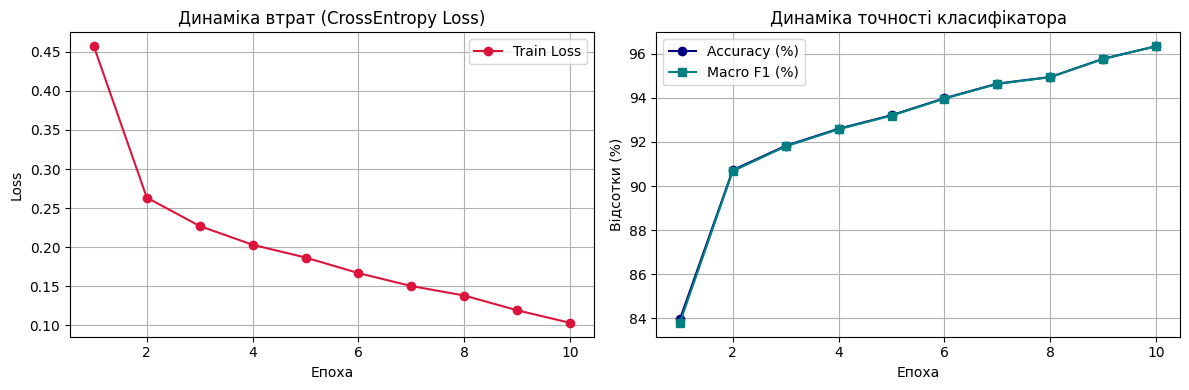


--------------------------------------------------
 РЕЗУЛЬТАТИ ПРЯМОЇ КЛАСИФІКАЦІЇ (ТЕСТОВИЙ НАБІР)
--------------------------------------------------
              precision    recall  f1-score   support

 T-shirt/top     0.8999    0.8720    0.8857      1000
     Trouser     0.9950    0.9920    0.9935      1000
    Pullover     0.9046    0.9010    0.9028      1000
       Dress     0.9211    0.9450    0.9329      1000
        Coat     0.8769    0.9050    0.8907      1000
      Sandal     0.9831    0.9910    0.9871      1000
       Shirt     0.8131    0.7920    0.8024      1000
     Sneaker     0.9581    0.9830    0.9704      1000
         Bag     0.9851    0.9910    0.9880      1000
  Ankle boot     0.9896    0.9560    0.9725      1000

    accuracy                         0.9328     10000
   macro avg     0.9327    0.9328    0.9326     10000
weighted avg     0.9327    0.9328    0.9326     10000



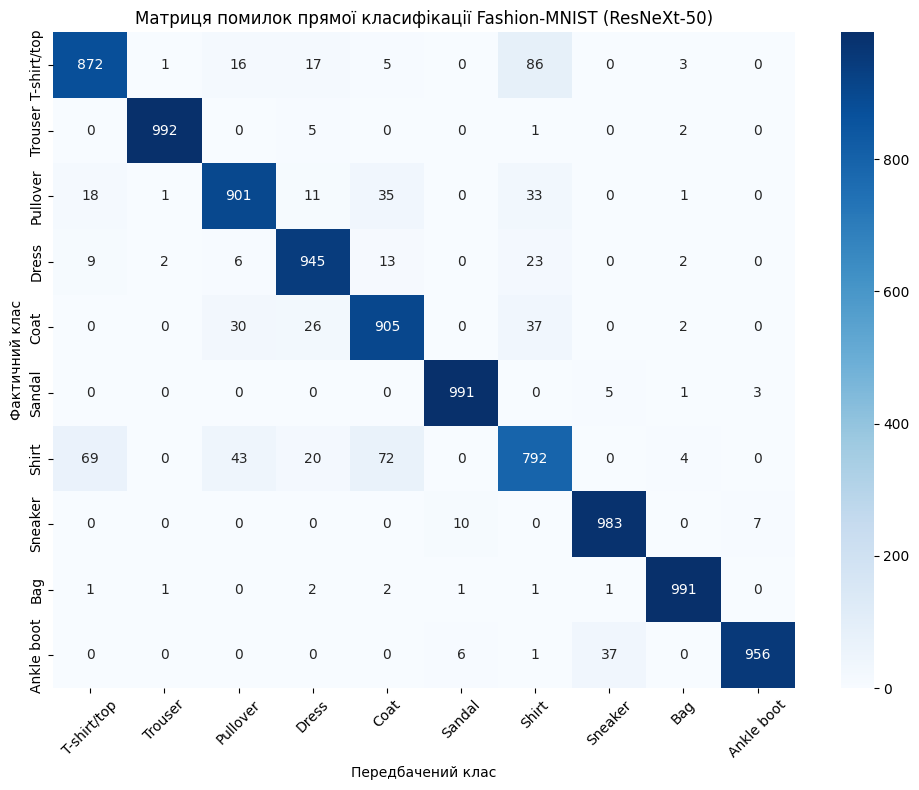

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_cls + 1), cls_history['loss'], marker='o', color='crimson', label='Train Loss')
plt.title('Динаміка втрат (CrossEntropy Loss)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_cls + 1), cls_history['acc'], marker='o', color='navy', label='Accuracy (%)')
plt.plot(range(1, epochs_cls + 1), cls_history['f1'], marker='s', color='teal', label='Macro F1 (%)')
plt.title('Динаміка точності класифікатора')
plt.xlabel('Епоха')
plt.ylabel('Відсотки (%)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('direct_classification_learning_curves.png')
plt.show()

cls_model.eval()
all_preds_cls = []
all_targets_cls = []

with torch.no_grad():
    for imgs, labels in test_loader_cls:
        imgs = imgs.to(device)
        outputs = cls_model(imgs)
        _, predicted = outputs.max(1)
        all_preds_cls.extend(predicted.cpu().numpy())
        all_targets_cls.extend(labels.numpy())

print("\n" + "-" * 50)
print(" РЕЗУЛЬТАТИ ПРЯМОЇ КЛАСИФІКАЦІЇ (ТЕСТОВИЙ НАБІР)")
print("-" * 50)
print(classification_report(all_targets_cls, all_preds_cls, target_names=categories, digits=4))

cm_cls = confusion_matrix(all_targets_cls, all_preds_cls)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cls, annot=True, fmt='d', cmap='Blues',
            xticklabels=categories, yticklabels=categories)
plt.title('Матриця помилок прямої класифікації Fashion-MNIST (ResNeXt-50)')
plt.xlabel('Передбачений клас')
plt.ylabel('Фактичний клас')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('direct_classification_confusion_matrix.png')
plt.show()


In [ ]:
print("\n" + "=" * 80)
print("ЧАСТИНА 2: НАВЧАННЯ СІАМСЬКОЇ МЕРЕЖІ ТА t-SNE АНАЛІЗ")
print("=" * 80)

feature_extractor = get_feature_extractor(model_type=MODEL_MODE, feature_dim=FEATURE_DIM)
siamese_model = SiameseNet(feature_extractor, feature_dim=FEATURE_DIM).to(device)

siamese_dataset = SiameseFashionMNIST(train_mnist)
train_loader_siam = DataLoader(siamese_dataset, batch_size=64, shuffle=True)
test_raw_loader = DataLoader(test_mnist, batch_size=256, shuffle=False)

criterion_siam = nn.BCELoss()
optimizer_siam = optim.Adam(siamese_model.parameters(), lr=1e-3)

siam_history = {'loss': [], 'mae': [], 'acc': [], 'f1': []}

epochs_siam = 10
for epoch in range(epochs_siam):
    siamese_model.train()
    running_loss = 0.0
    running_mae = 0.0
    all_siam_targets = []
    all_siam_preds_binary = []

    for img_a, img_b, target in train_loader_siam:
        img_a, img_b, target = img_a.to(device), img_b.to(device), target.to(device)

        optimizer_siam.zero_grad()
        outputs = siamese_model(img_a, img_b)
        loss = criterion_siam(outputs, target)
        loss.backward()
        optimizer_siam.step()

        running_loss += loss.item() * img_a.size(0)
        running_mae += torch.sum(torch.abs(outputs - target)).item()

        preds_binary = (outputs >= 0.5).float()
        all_siam_preds_binary.extend(preds_binary.cpu().numpy().squeeze())
        all_siam_targets.extend(target.cpu().numpy().squeeze())

    epoch_loss = running_loss / len(siamese_dataset)
    epoch_mae = running_mae / len(siamese_dataset)
    epoch_acc = accuracy_score(all_siam_targets, all_siam_preds_binary)
    p_siam, r_siam, f1_siam, _ = precision_recall_fscore_support(
        all_siam_targets, all_siam_preds_binary, average='binary', zero_division=0
    )

    siam_history['loss'].append(epoch_loss)
    siam_history['mae'].append(epoch_mae)
    siam_history['acc'].append(epoch_acc * 100)
    siam_history['f1'].append(f1_siam * 100)

    print(f"Epoch [{epoch+1}/{epochs_siam}] "
          f"| Loss: {epoch_loss:.4f} "
          f"| MAE: {epoch_mae:.4f} "
          f"| Acc: {epoch_acc*100:.2f}% "
          f"| Precision: {p_siam:.4f} "
          f"| Recall: {r_siam:.4f} "
          f"| F1-Score: {f1_siam:.4f}")

print("\n--- Навчання Сіамської мережі завершено! ---")


 ЧАСТИНА 2: НАВЧАННЯ СІАМСЬКОЇ МЕРЕЖІ ТА t-SNE АНАЛІЗ
Ініціалізація ВЛАСНОЇ архітектури ResNeXt-50...
Epoch [1/10] | Loss: 0.5081 | MAE: 0.3620 | Acc: 72.92% | Precision: 0.6660 | Recall: 0.9190 | F1-Score: 0.7723
Epoch [2/10] | Loss: 0.3299 | MAE: 0.2164 | Acc: 85.56% | Precision: 0.8115 | Recall: 0.9295 | F1-Score: 0.8665
Epoch [3/10] | Loss: 0.2699 | MAE: 0.1709 | Acc: 88.59% | Precision: 0.8532 | Recall: 0.9300 | F1-Score: 0.8899
Epoch [4/10] | Loss: 0.2305 | MAE: 0.1437 | Acc: 90.31% | Precision: 0.8772 | Recall: 0.9377 | F1-Score: 0.9065
Epoch [5/10] | Loss: 0.2124 | MAE: 0.1310 | Acc: 91.16% | Precision: 0.8877 | Recall: 0.9419 | F1-Score: 0.9140
Epoch [6/10] | Loss: 0.1960 | MAE: 0.1199 | Acc: 91.81% | Precision: 0.8960 | Recall: 0.9462 | F1-Score: 0.9204
Epoch [7/10] | Loss: 0.1797 | MAE: 0.1094 | Acc: 92.52% | Precision: 0.9095 | Recall: 0.9438 | F1-Score: 0.9263
Epoch [8/10] | Loss: 0.1736 | MAE: 0.1047 | Acc: 92.78% | Precision: 0.9145 | Recall: 0.9442 | F1-Score: 0.9291
E

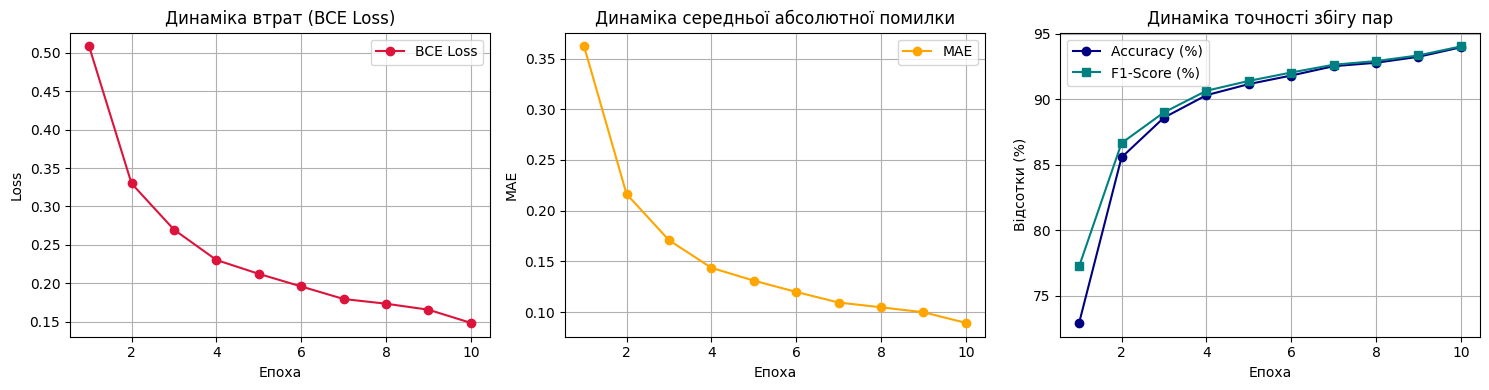


      ТОЧНІ ФІНАЛЬНІ ПОКАЗНИКИ ЯКОСТІ МЕРЕЖІ
ROC-AUC Score: 0.9866

Детальний звіт класифікації (Classification Report):
                 precision    recall  f1-score   support

Різні класи (0)     0.9323    0.9478    0.9400      4957
  Один клас (1)     0.9478    0.9324    0.9400      5043

       accuracy                         0.9400     10000
      macro avg     0.9401    0.9401    0.9400     10000
   weighted avg     0.9401    0.9400    0.9400     10000



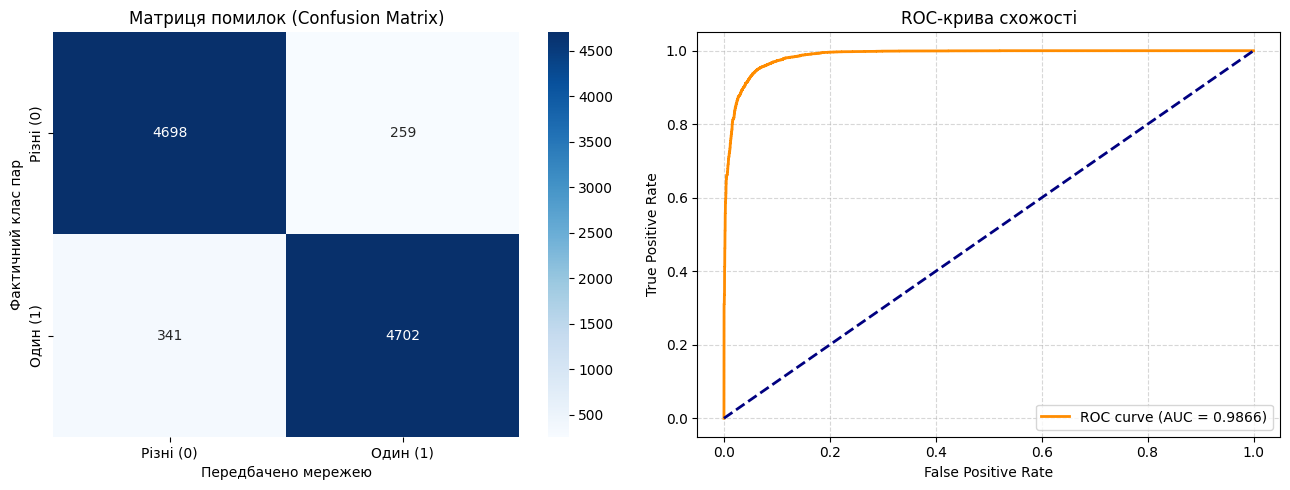


Візуалізація передбачень схожості пар зображень...


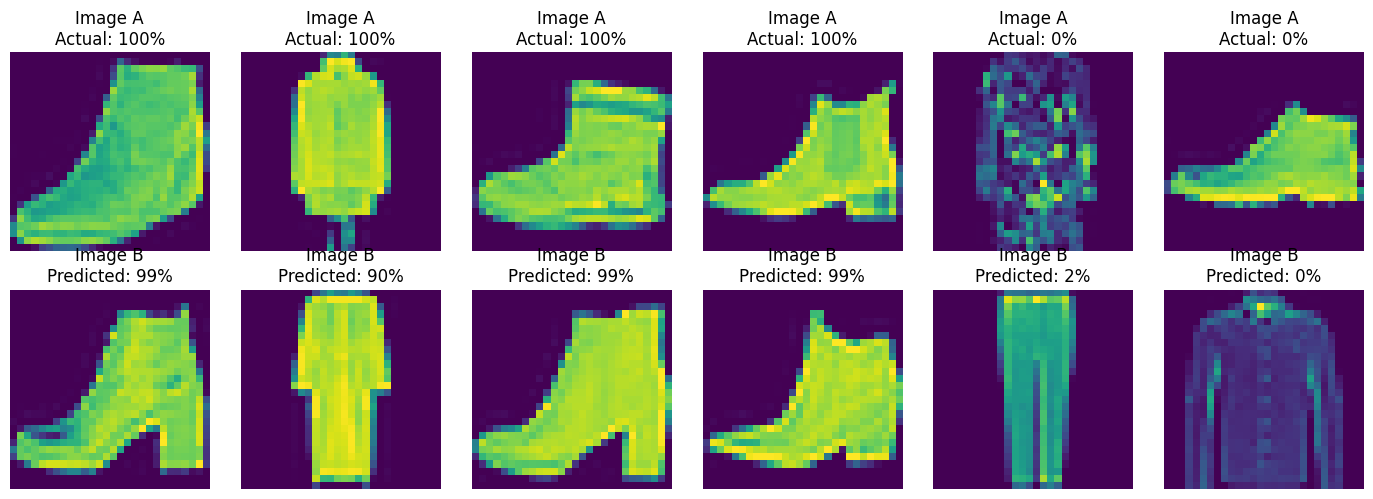


Генерація t-SNE графіка для векторів ознак...
Обчислення t-SNE проекції на 2D площину...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.001s...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computed neighbors for 10000 samples in 0.949s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 0.131606
[t-SNE] KL divergence after 250 iterations with early exaggeration: 68.626717
[t-SNE] KL divergence after 500 iterations: 1.298642


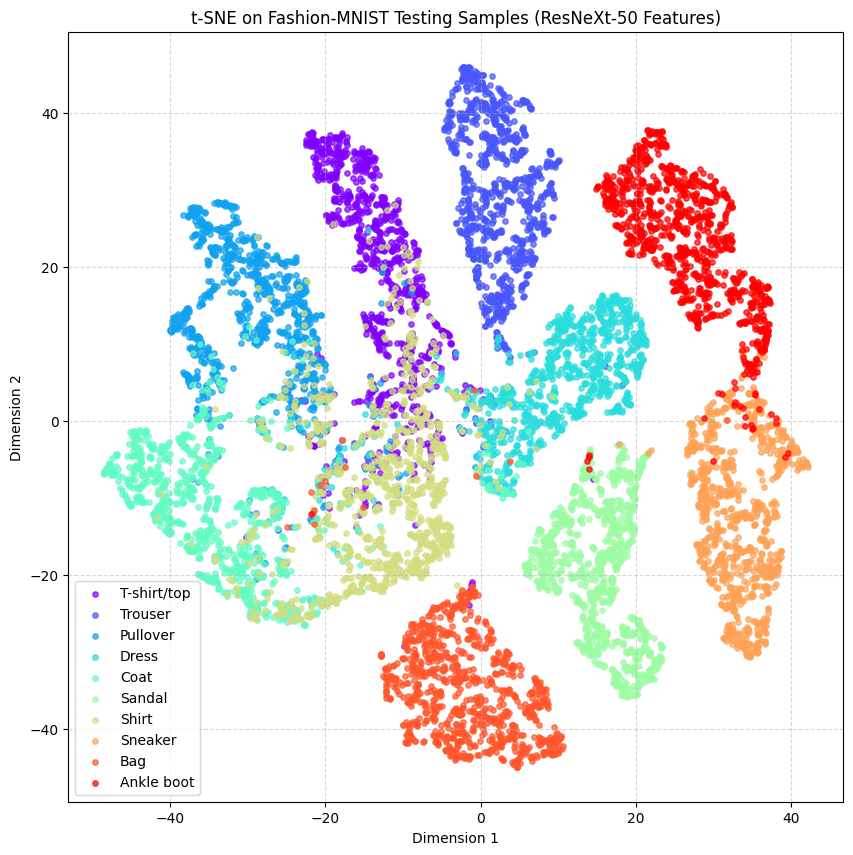

In [ ]:
  plt.figure(figsize=(15, 4))
  plt.subplot(1, 3, 1)
  plt.plot(range(1, epochs_siam + 1), siam_history['loss'], marker='o', color='crimson', label='BCE Loss')
  plt.title('Динаміка втрат (BCE Loss)')
  plt.xlabel('Епоха')
  plt.ylabel('Loss')
  plt.grid(True)
  plt.legend()

  plt.subplot(1, 3, 2)
  plt.plot(range(1, epochs_siam + 1), siam_history['mae'], marker='o', color='orange', label='MAE')
  plt.title('Динаміка середньої абсолютної помилки')
  plt.xlabel('Епоха')
  plt.ylabel('MAE')
  plt.grid(True)
  plt.legend()

  plt.subplot(1, 3, 3)
  plt.plot(range(1, epochs_siam + 1), siam_history['acc'], marker='o', color='navy', label='Accuracy (%)')
  plt.plot(range(1, epochs_siam + 1), siam_history['f1'], marker='s', color='teal', label='F1-Score (%)')
  plt.title('Динаміка точності збігу пар')
  plt.xlabel('Епоха')
  plt.ylabel('Відсотки (%)')
  plt.grid(True)
  plt.legend()
  plt.tight_layout()
  plt.savefig('siamese_learning_curves.png')
  plt.show()

  evaluate_siamese_metrics(siamese_model, test_mnist, device)

  print("\nВізуалізація передбачень схожості пар зображень...")
  show_model_predictions(siamese_model, test_mnist, device, examples_amount=6)

  print("\nГенерація t-SNE графіка для векторів ознак...")
  visualize_tsne(feature_extractor, test_raw_loader, device)